In [51]:
print('hola')

hola


In [52]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [53]:
import os

ruta = '../data/raw/accidentes.csv'

print(f"Existe: {os.path.exists(ruta)}")
print(f"Tamaño: {os.path.getsize(ruta)} bytes")

with open(ruta, 'rb') as f:
    firma = f.read(8)
    print(f"Primeros bytes (hex): {firma.hex()}")
    print(f"Primeros bytes (texto): {firma}")

Existe: True
Tamaño: 46524398 bytes
Primeros bytes (hex): 434f424552545552
Primeros bytes (texto): b'COBERTUR'


In [54]:
df = pd.read_csv(ruta, encoding='utf-8-sig')
df.head()

,COBERTURA,ID_ENTIDAD,ID_MUNICIPIO,ANIO,MES,ID_HORA,ID_MINUTO,ID_DIA,DIASEMANA,URBANA,...,PEATMUERTO,PEATHERIDO,CICLMUERTO,CICLHERIDO,OTROMUERTO,OTROHERIDO,NEMUERTO,NEHERIDO,CLASACC,ESTATUS
0,Municipal,1,1,2015,Enero,20,40,27,Martes,Accidente en no intersección,...,0,0,0,0,0,0,0,0,Sólo Daños,Cifras definitivas
1,Municipal,1,1,2015,Enero,0,0,1,Jueves,Accidente en no intersección,...,0,0,0,0,0,0,0,0,Sólo Daños,Cifras definitivas
2,Municipal,1,1,2015,Enero,17,0,28,Miércoles,Accidente en intersección,...,0,0,0,0,0,0,0,0,No fatal,Cifras definitivas
3,Municipal,1,1,2015,Enero,8,40,1,Jueves,Accidente en no intersección,...,0,0,0,0,0,0,0,0,Sólo Daños,Cifras definitivas
4,Municipal,1,1,2015,Enero,23,40,30,Viernes,Accidente en intersección,...,0,0,0,0,0,0,0,0,Sólo Daños,Cifras definitivas


In [55]:
mapa_meses = {
    'Enero': 1, 'Febrero': 2, 'Marzo': 3, 'Abril': 4,
    'Mayo': 5, 'Junio': 6, 'Julio': 7, 'Agosto': 8,
    'Septiembre': 9, 'Octubre': 10, 'Noviembre': 11, 'Diciembre': 12
}

df['id_mes'] = df['MES'].map(mapa_meses)
df.head()

,COBERTURA,ID_ENTIDAD,ID_MUNICIPIO,ANIO,MES,ID_HORA,ID_MINUTO,ID_DIA,DIASEMANA,URBANA,...,PEATHERIDO,CICLMUERTO,CICLHERIDO,OTROMUERTO,OTROHERIDO,NEMUERTO,NEHERIDO,CLASACC,ESTATUS,id_mes
0,Municipal,1,1,2015,Enero,20,40,27,Martes,Accidente en no intersección,...,0,0,0,0,0,0,0,Sólo Daños,Cifras definitivas,1
1,Municipal,1,1,2015,Enero,0,0,1,Jueves,Accidente en no intersección,...,0,0,0,0,0,0,0,Sólo Daños,Cifras definitivas,1
2,Municipal,1,1,2015,Enero,17,0,28,Miércoles,Accidente en intersección,...,0,0,0,0,0,0,0,No fatal,Cifras definitivas,1
3,Municipal,1,1,2015,Enero,8,40,1,Jueves,Accidente en no intersección,...,0,0,0,0,0,0,0,Sólo Daños,Cifras definitivas,1
4,Municipal,1,1,2015,Enero,23,40,30,Viernes,Accidente en intersección,...,0,0,0,0,0,0,0,Sólo Daños,Cifras definitivas,1


In [56]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 180066 entries, 0 to 180065
Data columns (total 46 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   COBERTURA     180066 non-null  str  
 1   ID_ENTIDAD    180066 non-null  int64
 2   ID_MUNICIPIO  180066 non-null  int64
 3   ANIO          180066 non-null  int64
 4   MES           180066 non-null  str  
 5   ID_HORA       180066 non-null  int64
 6   ID_MINUTO     180066 non-null  int64
 7   ID_DIA        180066 non-null  int64
 8   DIASEMANA     180066 non-null  str  
 9   URBANA        180066 non-null  str  
 10  SUBURBANA     180066 non-null  str  
 11  TIPACCID      180066 non-null  str  
 12  AUTOMOVIL     180066 non-null  int64
 13  CAMPASAJ      180066 non-null  int64
 14  MICROBUS      180066 non-null  int64
 15  PASCAMION     180066 non-null  int64
 16  OMNIBUS       180066 non-null  int64
 17  TRANVIA       180066 non-null  int64
 18  CAMIONETA     180066 non-null  int64
 19  CAMION       

In [57]:
# 1. Construye la cadena tal como la estás haciendo
df['fecha_str'] = (
    df['ANIO'].astype(str)+ '-' +
    df['id_mes'].astype(str).str.zfill(2)+ '-' +
    df['ID_DIA'].astype(str).str.zfill(2)
)

# 2. Busca los que NO cumplen con el patrón esperado (YYYY-MM-DD)
import re
patron_valido = r'^\d{4}-\d{2}-\d{2}$'

df['es_valido'] = df['fecha_str'].str.match(patron_valido, na=False)

# 3. Muestra los registros problemáticos
print("Registros problemáticos:")
print(df[~df['es_valido']][['ANIO', 'id_mes', 'ID_DIA', 'fecha_str']].head(20))

Registros problemáticos:
Empty DataFrame
Columns: [ANIO, id_mes, ID_DIA, fecha_str]
Index: []


In [58]:
df.head()

,COBERTURA,ID_ENTIDAD,ID_MUNICIPIO,ANIO,MES,ID_HORA,ID_MINUTO,ID_DIA,DIASEMANA,URBANA,...,CICLHERIDO,OTROMUERTO,OTROHERIDO,NEMUERTO,NEHERIDO,CLASACC,ESTATUS,id_mes,fecha_str,es_valido
0,Municipal,1,1,2015,Enero,20,40,27,Martes,Accidente en no intersección,...,0,0,0,0,0,Sólo Daños,Cifras definitivas,1,2015-01-27,True
1,Municipal,1,1,2015,Enero,0,0,1,Jueves,Accidente en no intersección,...,0,0,0,0,0,Sólo Daños,Cifras definitivas,1,2015-01-01,True
2,Municipal,1,1,2015,Enero,17,0,28,Miércoles,Accidente en intersección,...,0,0,0,0,0,No fatal,Cifras definitivas,1,2015-01-28,True
3,Municipal,1,1,2015,Enero,8,40,1,Jueves,Accidente en no intersección,...,0,0,0,0,0,Sólo Daños,Cifras definitivas,1,2015-01-01,True
4,Municipal,1,1,2015,Enero,23,40,30,Viernes,Accidente en intersección,...,0,0,0,0,0,Sólo Daños,Cifras definitivas,1,2015-01-30,True


In [59]:
df[df['es_valido']==False]

,COBERTURA,ID_ENTIDAD,ID_MUNICIPIO,ANIO,MES,ID_HORA,ID_MINUTO,ID_DIA,DIASEMANA,URBANA,...,CICLHERIDO,OTROMUERTO,OTROHERIDO,NEMUERTO,NEHERIDO,CLASACC,ESTATUS,id_mes,fecha_str,es_valido


In [60]:
# 1. Construye la columna de texto
df['fecha_str'] = (
    df['ANIO'].astype(str) + '-' +
    df['id_mes'].astype(str).str.zfill(2) + '-' +
    df['ID_DIA'].astype(str).str.zfill(2)
)

# 2. Intenta la conversión con errors='coerce' para no romper la ejecución
df['fecha'] = pd.to_datetime(df['fecha_str'], format='%Y-%m-%d', errors='coerce')

# 3. Revisa si quedaron NaT
problemas = df[df['fecha'].isna()]
print(f"Registros que fallaron: {len(problemas)}")

# 4. Si hay problemas, mira el repr exacto (revela caracteres invisibles)
if not problemas.empty:
    for idx, row in problemas.head(5).iterrows():
        print(f"Índice {idx}: {repr(row['fecha_str'])}")

Registros que fallaron: 2118
Índice 145507: '2015-01-32'
Índice 145508: '2015-01-32'
Índice 145509: '2015-01-32'
Índice 145510: '2015-01-32'
Índice 145511: '2015-01-32'


In [61]:
print(problemas)

        COBERTURA  ID_ENTIDAD  ID_MUNICIPIO  ANIO        MES  ID_HORA  \
145507  Municipal          14            67  2015      Enero       99   
145508  Municipal          14            67  2015      Enero       99   
145509  Municipal          14            67  2015      Enero       99   
145510  Municipal          14            67  2015      Enero       99   
145511  Municipal          14            67  2015      Enero       99   
...           ...         ...           ...   ...        ...      ...   
148991  Municipal          14            67  2015  Diciembre       99   
148992  Municipal          14            67  2015  Diciembre       99   
148993  Municipal          14            67  2015  Diciembre       99   
148994  Municipal          14            67  2015  Diciembre       99   
148995  Municipal          14            67  2015  Diciembre       99   

        ID_MINUTO  ID_DIA        DIASEMANA                     URBANA  ...  \
145507         99      32  No especificado  A

In [62]:
# 1. Convertir a datetime, forzando los inválidos a NaT
df['fecha'] = pd.to_datetime(df['fecha_str'], format='%Y-%m-%d', errors='coerce')

# 2. Filtrar el DataFrame para quedarnos solo con las fechas válidas
df_fechas = df.dropna(subset=['fecha']).reset_index(drop=True)

# 3. Verificar que ya no queden NaT
print(f"Registros restantes: {len(df_fechas)}")
print(f"NaT restantes: {df_fechas['fecha'].isna().sum()}")

Registros restantes: 177948
NaT restantes: 0


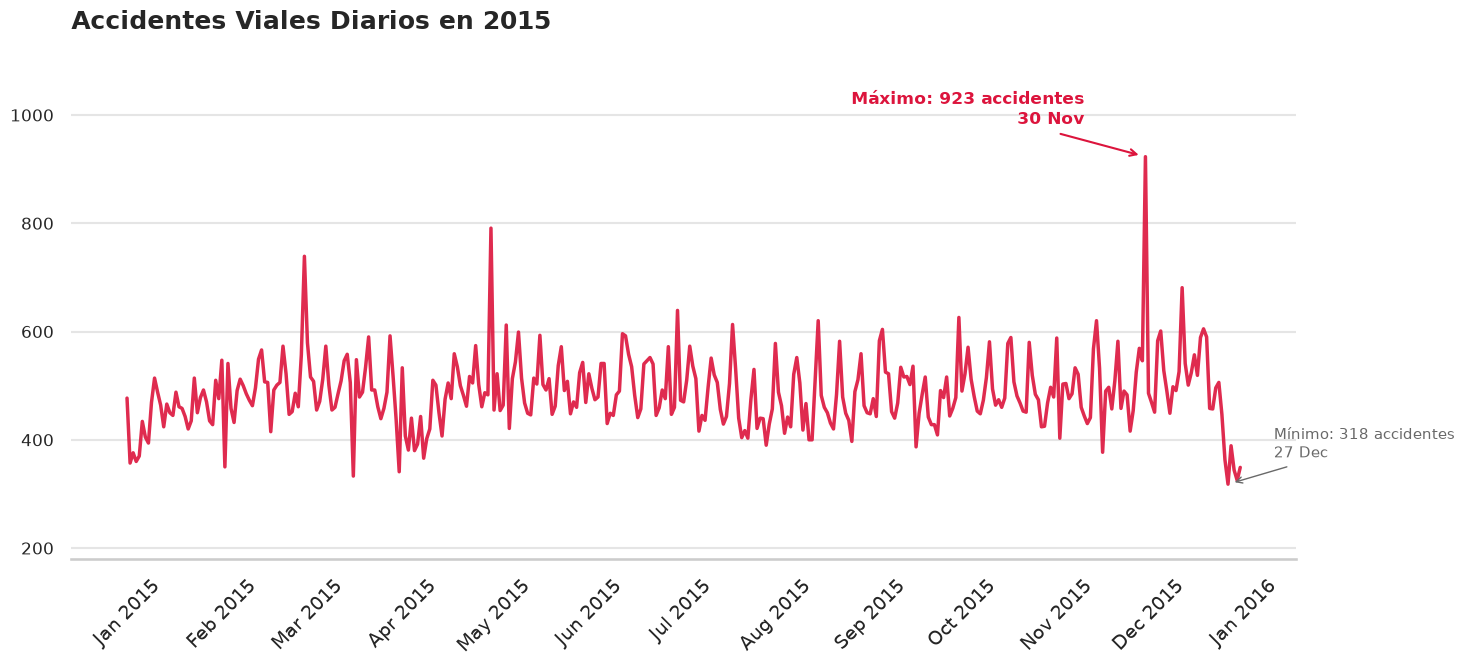

In [71]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import pandas as pd

# 1. Asegurar el estilo
sns.set_theme(style="whitegrid", context="talk")
sns.set_palette("pastel")

# 2. Agrupar por fecha para contar accidentes diarios
accidentes_por_dia = df_fechas.groupby('fecha').size().reset_index(name='total_accidentes')

# 3. Crear la figura
fig, ax = plt.subplots(figsize=(15, 7))

# 4. Graficar línea de tiempo
sns.lineplot(
    data=accidentes_por_dia, 
    x='fecha', 
    y='total_accidentes', 
    ax=ax, 
    color='crimson',
    linewidth=2.5, 
    alpha=0.9
)

# 5. Ajustes estéticos
ax.set_title('Accidentes Viales Diarios en 2015', fontsize=18, fontweight='bold', loc='left', pad=20)
ax.set_xlabel('') 
ax.set_ylabel('') 
ax.tick_params(axis='y', labelsize=12) 

# Formatear el eje X
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.xticks(rotation=45, fontsize=14) 

# 6. Encontrar los valores extremos
max_acc = accidentes_por_dia.loc[accidentes_por_dia['total_accidentes'].idxmax()]
min_acc = accidentes_por_dia.loc[accidentes_por_dia['total_accidentes'].idxmin()]

# --- AJUSTE DEL ESPACIO DEL EJE Y ---
# Damos un margen del 20% arriba y abajo para que las anotaciones respiren
max_y = accidentes_por_dia['total_accidentes'].max()
min_y = accidentes_por_dia['total_accidentes'].min()
ax.set_ylim(min_y - (max_y * 0.15), max_y + (max_y * 0.20))

# 7. Anotaciones corregidas
# Máximo: Desplazamos el texto a la izquierda para que no se salga por arriba ni por la derecha
ax.annotate(
    f'Máximo: {max_acc["total_accidentes"]} accidentes\n{max_acc["fecha"].strftime("%d %b")}',
    xy=(max_acc['fecha'], max_acc['total_accidentes']),
    xytext=(max_acc['fecha'] - pd.Timedelta(days=20), max_acc['total_accidentes'] + 50), # Texto 20 días a la izquierda y 50 puntos arriba
    ha='right', va='bottom', 
    fontsize=12, fontweight='bold', color='crimson',
    arrowprops=dict(arrowstyle='->', color='crimson', lw=1.5, shrinkB=5) # shrinkB acorta la flecha
)

# Mínimo: Desplazamos el texto a la derecha y arriba para evitar que choque con las fechas
ax.annotate(
    f'Mínimo: {min_acc["total_accidentes"]} accidentes\n{min_acc["fecha"].strftime("%d %b")}',
    xy=(min_acc['fecha'], min_acc['total_accidentes']),
    xytext=(min_acc['fecha'] + pd.Timedelta(days=15), min_acc['total_accidentes'] + 40), # Texto 15 días a la derecha y 40 puntos arriba
    ha='left', va='bottom', 
    fontsize=11, color='dimgray',
    arrowprops=dict(arrowstyle='->', color='dimgray', lw=1, shrinkB=5)
)

# 8. Limpieza visual
ax.grid(axis='x', visible=False)
ax.grid(axis='y', visible=True, alpha=0.5)
sns.despine(left=True, top=True, right=True)

plt.tight_layout()
plt.show()

In [5]:
df["DIASEMANA"].value_counts()

DIASEMANA
Sábado             28773
Viernes            26447
Domingo            25765
Jueves             24757
Lunes              24485
Martes             24138
Miércoles          23583
No especificado     2118
Name: count, dtype: int64

In [6]:
df.shape

(180066, 45)

In [7]:
df.columns

Index(['COBERTURA', 'ID_ENTIDAD', 'ID_MUNICIPIO', 'ANIO', 'MES', 'ID_HORA',
       'ID_MINUTO', 'ID_DIA', 'DIASEMANA', 'URBANA', 'SUBURBANA', 'TIPACCID',
       'AUTOMOVIL', 'CAMPASAJ', 'MICROBUS', 'PASCAMION', 'OMNIBUS', 'TRANVIA',
       'CAMIONETA', 'CAMION', 'TRACTOR', 'FERROCARRI', 'MOTOCICLET',
       'BICICLETA', 'OTROVEHIC', 'CAUSAACCI', 'CAPAROD', 'SEXO', 'ALIENTO',
       'CINTURON', 'ID_EDAD', 'CONDMUERTO', 'CONDHERIDO', 'PASAMUERTO',
       'PASAHERIDO', 'PEATMUERTO', 'PEATHERIDO', 'CICLMUERTO', 'CICLHERIDO',
       'OTROMUERTO', 'OTROHERIDO', 'NEMUERTO', 'NEHERIDO', 'CLASACC',
       'ESTATUS'],
      dtype='str')

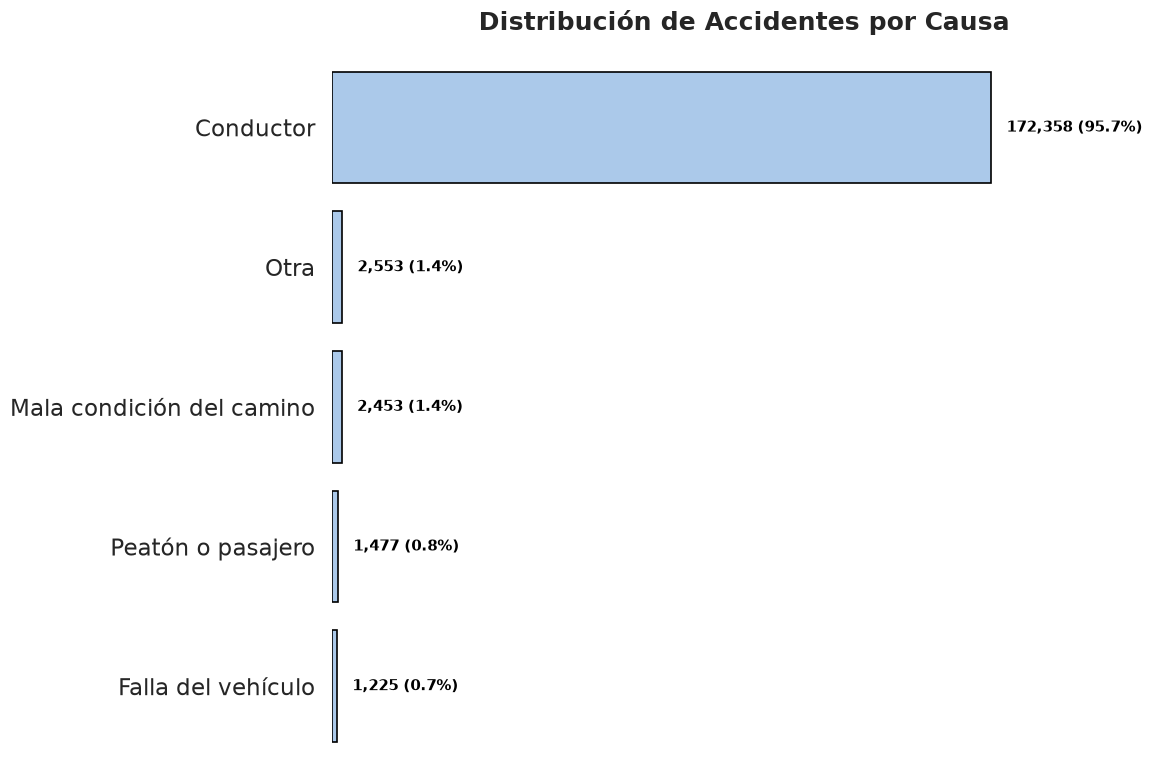

In [8]:


# 1. Aplicar el estilo de Seaborn
sns.set_theme(style="whitegrid", context="talk")
sns.set_palette("pastel")

# 2. Calcular los conteos y porcentajes
conteo_causas = df['CAUSAACCI'].value_counts(dropna=False)
total_causas = conteo_causas.sum()
porcentajes = (conteo_causas / total_causas * 100).round(1)

# 3. Crear la figura (más alta para que quepan todas las causas)
fig, ax = plt.subplots(figsize=(12, 8))

# 4. Dibujar el gráfico de barras HORIZONTAL
sns.barplot(
    x=conteo_causas.values, 
    y=conteo_causas.index, 
    ax=ax,
    edgecolor='black',
    linewidth=1.2
)

# 5. Añadir las etiquetas (conteo exacto y porcentaje)
for i, (valor, pct) in enumerate(zip(conteo_causas.values, porcentajes.values)):
    # En gráfico horizontal, el texto va a la derecha de la barra (valor + un margen)
    margen = total_causas * 0.015
    ax.text(
        valor + margen, i, 
        f' {valor:,} ({pct}%)', 
        ha='left', va='center', 
        fontweight='bold', fontsize=11, color='black'
    )

# 6. Ajustes estéticos finales
ax.set_title('Distribución de Accidentes por Causa', fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('') 
ax.set_ylabel('') 

# --- MODIFICACIÓN: Eliminar los valores del eje X (por ser barras horizontales) ---
ax.set_xticks([]) 

# Ajustar el límite del eje X para que las etiquetas no se corten
ax.set_xlim(0, conteo_causas.max() * 1.25)

# Quitar la cuadrícula en ambos ejes para un look más limpio
ax.grid(False) 

# Quitar los bordes (incluyendo el inferior, que es donde estaban los valores)
sns.despine(left=True, top=True, right=True, bottom=True)

plt.tight_layout()
plt.show()

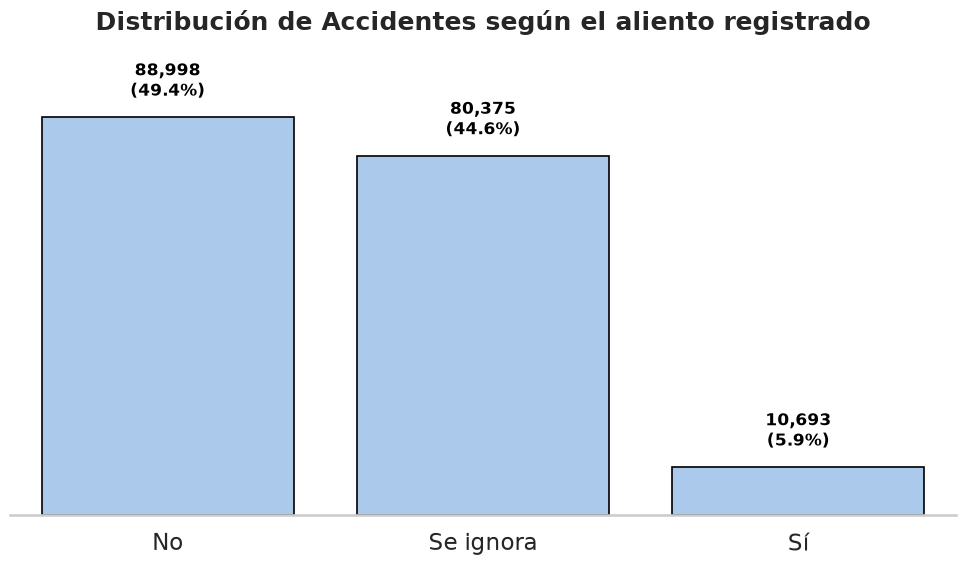

In [9]:
# 1. Aplicar el estilo de Seaborn
sns.set_theme(style="whitegrid", context="talk")
sns.set_palette("pastel")

# 2. Calcular los conteos y porcentajes
# (Usamos dropna=False por si hay valores nulos, para que no desaparezcan)
conteo_aliento = df['ALIENTO'].value_counts(dropna=False)
total = conteo_aliento.sum()
porcentajes = (conteo_aliento / total * 100).round(1)

# 3. Crear la figura
fig, ax = plt.subplots(figsize=(10, 6))

# 4. Dibujar el gráfico de barras
sns.barplot(
    x=conteo_aliento.index, 
    y=conteo_aliento.values, 
    ax=ax,
    edgecolor='black', # Borde negro para que resalten
    linewidth=1.2
)

# 5. Añadir las etiquetas con el conteo exacto y el porcentaje
for i, (valor, pct) in enumerate(zip(conteo_aliento.values, porcentajes.values)):
    # Posicionamos el texto un poco arriba de la barra (valor + 2% del total para dar aire)
    ax.text(
        i, valor + (total * 0.02), 
        f'{valor:,}\n({pct}%)', 
        ha='center', va='bottom', 
        fontweight='bold', fontsize=12, color='black'
    )

# 6. Ajustes estéticos finales
ax.set_title('Distribución de Accidentes según el aliento registrado', fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('') # Quitamos el título del eje X porque las categorías son obvias
ax.set_ylabel('')
ax.set_yticks([]) 

# Ajustar el límite del eje Y para que las etiquetas no se corten
ax.set_ylim(0, total * 0.15 if total * 0.15 > conteo_aliento.max() else conteo_aliento.max() * 1.15)

# Quitar las líneas de la cuadrícula en el eje X para que se vea más limpio
ax.grid(axis='x', visible=False)

# Quitar los bordes superior e izquierdo (opcional, se ve más moderno)
sns.despine(left=True, top=True)

plt.tight_layout()
plt.show()

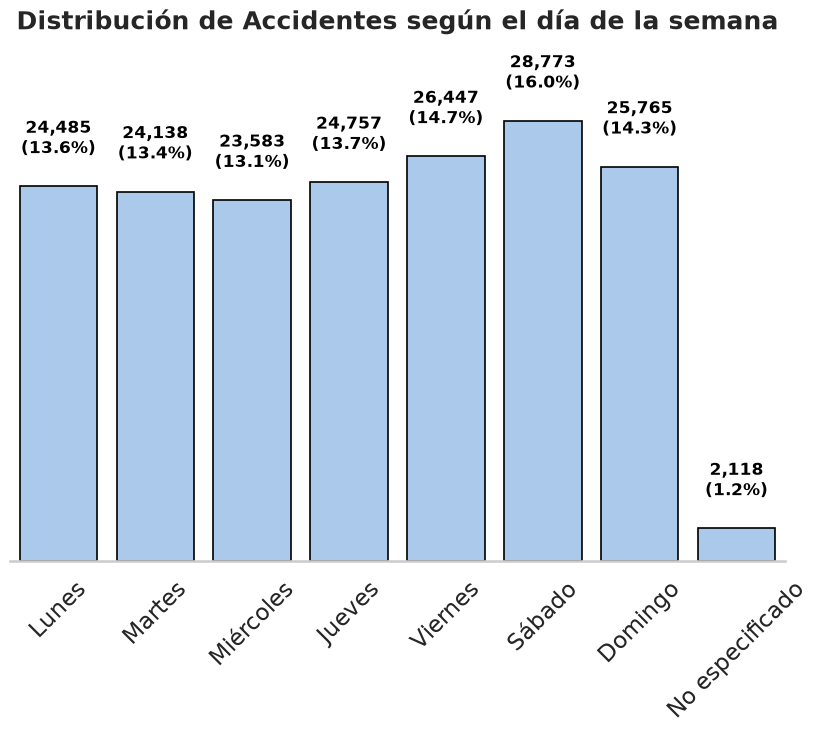

In [10]:
# 1. Aplicar el estilo de Seaborn
sns.set_theme(style="whitegrid", context="talk")
sns.set_palette("pastel")

# 2. Calcular los conteos y porcentajes

orden_dias = [
    "Lunes",
    "Martes",
    "Miércoles",
    "Jueves",
    "Viernes",
    "Sábado",
    "Domingo",
    "No especificado"
]

df['DIASEMANA'] = pd.Categorical(df['DIASEMANA'], categories=orden_dias, ordered=True)
conteo_dias_semana = df['DIASEMANA'].value_counts(sort=False)
total_dias = conteo_dias_semana.sum()
porcentajes_dias_semana = (conteo_dias_semana / total_dias * 100).round(1)

# 3. Crear la figura
fig, ax = plt.subplots(figsize=(10, 6))

# 4. Dibujar el gráfico de barras
sns.barplot(
    x=conteo_dias_semana.index, 
    y=conteo_dias_semana.values, 
    ax=ax,
    edgecolor='black', # Borde negro para que resalten
    linewidth=1.2
)

# 5. Añadir las etiquetas con el conteo exacto y el porcentaje
for i, (valor, pct) in enumerate(zip(conteo_dias_semana.values, porcentajes_dias_semana.values)):
    # Posicionamos el texto un poco arriba de la barra (valor + 2% del total para dar aire)
    ax.text(
        i, valor + (total * 0.01), 
        f'{valor:,}\n({pct}%)', 
        ha='center', va='bottom', 
        fontweight='bold', fontsize=12, color='black'
    )

# 6. Ajustes estéticos finales
ax.set_title('Distribución de Accidentes según el día de la semana', fontsize=18, fontweight='bold', pad=50)
ax.set_xlabel('') # Quitamos el título del eje X porque las categorías son obvias
ax.set_ylabel('') 
ax.set_yticks([]) 
plt.xticks(rotation=45)

# Quitar las líneas de la cuadrícula en el eje X para que se vea más limpio
ax.grid(axis='x', visible=False)

# Quitar los bordes superior e izquierdo (opcional, se ve más moderno)
sns.despine(left=True, top=True)

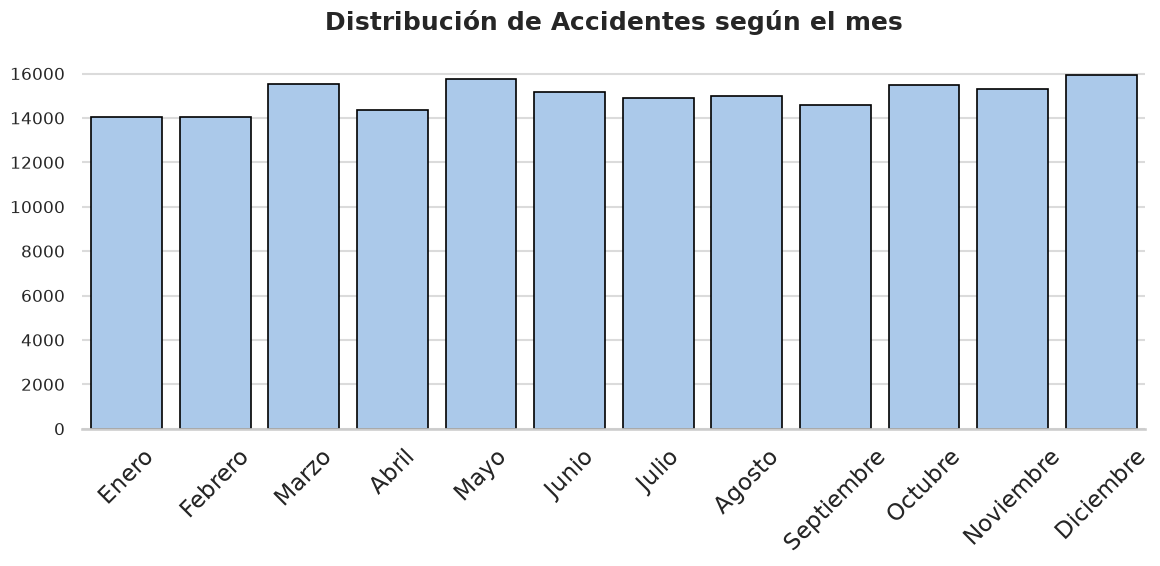

In [69]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Aplicar el estilo de Seaborn
sns.set_theme(style="whitegrid", context="talk")
sns.set_palette("pastel")

# 2. Calcular los conteos
orden_mes = [
    "Enero", "Febrero", "Marzo", "Abril", "Mayo", "Junio", 
    "Julio", "Agosto", "Septiembre", "Octubre", "Noviembre", "Diciembre"
]

df['MES'] = pd.Categorical(df['MES'], categories=orden_mes, ordered=True)
conteo_meses = df['MES'].value_counts(sort=False)

# 3. Crear la figura (un poco más alta para que respiren los ticks del eje Y)
fig, ax = plt.subplots(figsize=(12, 6))

# 4. Dibujar el gráfico de barras
sns.barplot(
    x=conteo_meses.index, 
    y=conteo_meses.values, 
    ax=ax,
    edgecolor='black', 
    linewidth=1.2
)

# 5. (ELIMINADO) Ya no iteramos para poner textos encima de las barras

# 6. Ajustes estéticos finales
# Bajamos el pad del título porque ya no necesitamos espacio para las etiquetas superiores
ax.set_title('Distribución de Accidentes según el mes', fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('') 
ax.set_ylabel('') 

# --- CAMBIO CLAVE: Habilitar los ticks del eje Y ---
# (Ya no usamos ax.set_yticks([]) )
# Opcional: Darle un poco de tamaño a los números del eje Y para que sean legibles
ax.tick_params(axis='y', labelsize=12) 

plt.xticks(rotation=45)

# Quitar las líneas de la cuadrícula en el eje X
ax.grid(axis='x', visible=False)
# Mantenemos o activamos la cuadrícula en Y (whitegrid la pone por defecto) para seguir la tendencia
ax.grid(axis='y', visible=True, alpha=0.7)

# Quitar los bordes superior, izquierdo y derecho
sns.despine(left=True, top=True, right=True)

plt.tight_layout()
plt.show()

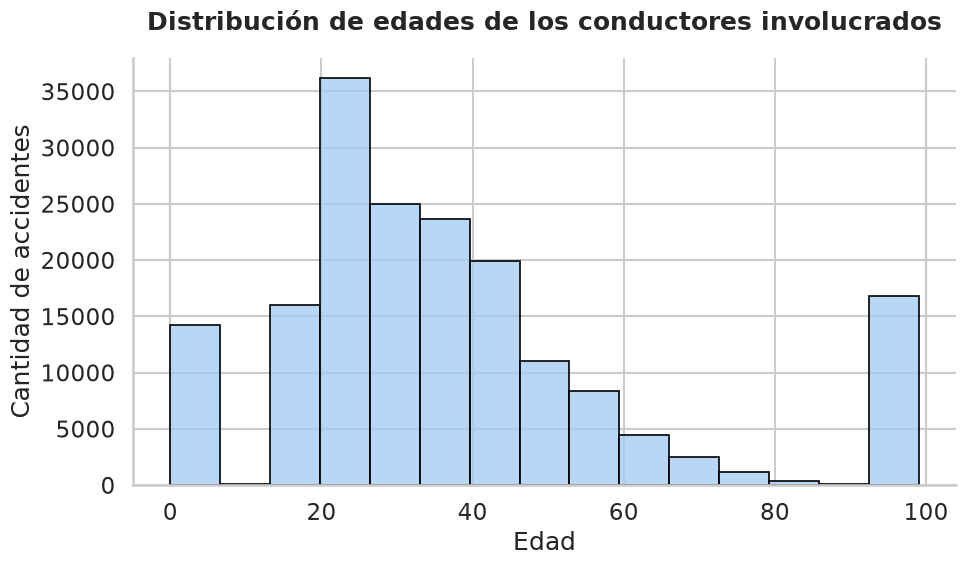

In [12]:
# Estilo
sns.set_theme(style="whitegrid", context="talk")
sns.set_palette("pastel")

# Figura
fig, ax = plt.subplots(figsize=(10, 6))

# Histograma
sns.histplot(
    df["ID_EDAD"],
    bins=15,
    kde=False,
    edgecolor='black',
    linewidth=1.2,
    ax=ax
)

# Títulos
ax.set_title(
    'Distribución de edades de los conductores involucrados',
    fontsize=18,
    fontweight='bold',
    pad=20
)

ax.set_xlabel('Edad')
ax.set_ylabel('Cantidad de accidentes')

sns.despine()

plt.tight_layout()
plt.show()

El histograma tiene muchos valores de 0 y 99, se hace un gráfico de barras con ambas columnas aparte y otro que elimina ambos valores

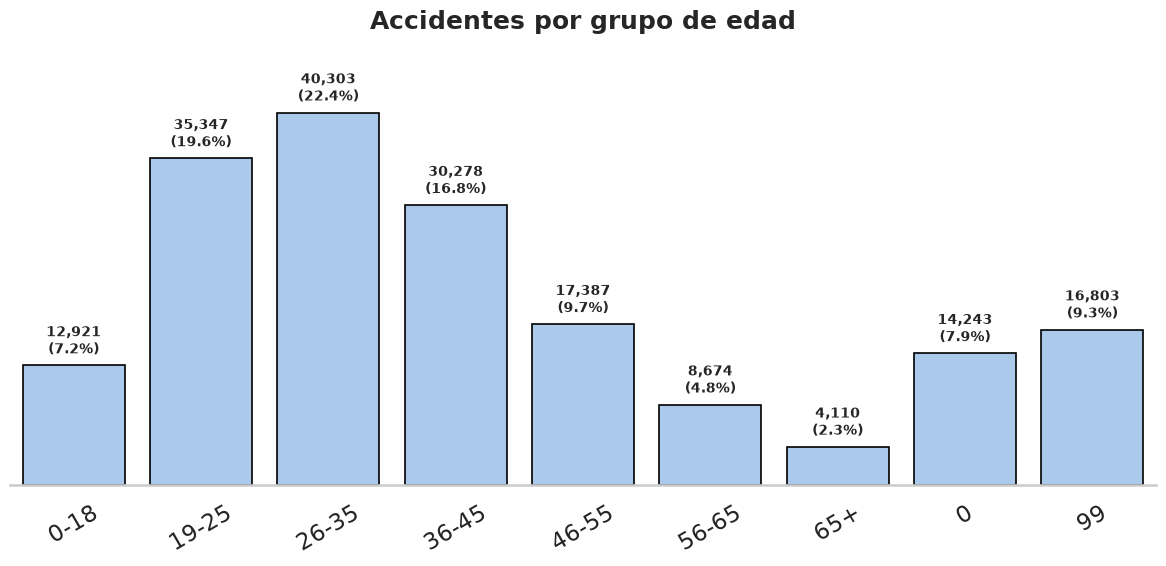

In [13]:
edad_grupo = pd.Series(index=df.index, dtype='object')

# Categorías especiales
edad_grupo[df['ID_EDAD'] == 0] = '0'
edad_grupo[df['ID_EDAD'] == 99] = '99'

# Edades válidas
mask = ~df['ID_EDAD'].isin([0, 99])

edad_grupo.loc[mask] = pd.cut(
    df.loc[mask, 'ID_EDAD'],
    bins=[0, 18, 25, 35, 45, 55, 65, 100],
    labels=[
        '0-18',
        '19-25',
        '26-35',
        '36-45',
        '46-55',
        '56-65',
        '65+'
    ]
).astype(str)

# Orden deseado
orden = [
    '0-18',
    '19-25',
    '26-35',
    '36-45',
    '46-55',
    '56-65',
    '65+',
    '0',
    '99'
]

conteos = edad_grupo.value_counts().reindex(orden).fillna(0)

porcentajes = (conteos / conteos.sum() * 100).round(1)

sns.set_theme(style="whitegrid", context="talk")
sns.set_palette("pastel")

fig, ax = plt.subplots(figsize=(12, 6))

sns.barplot(
    x=conteos.index,
    y=conteos.values,
    ax=ax,
    edgecolor='black',
    linewidth=1.2
)

# Etiquetas
for i, (valor, pct) in enumerate(zip(conteos.values, porcentajes.values)):
    ax.text(
        i,
        valor + conteos.max()*0.02,
        f'{int(valor):,}\n({pct}%)',
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

ax.set_title(
    'Accidentes por grupo de edad',
    fontsize=18,
    fontweight='bold',
    pad=20
)

ax.set_xlabel('')
ax.set_ylabel('')

ax.set_yticks([])

ax.set_ylim(0, conteos.max()*1.15)

ax.tick_params(axis='x', rotation=30)

ax.grid(axis='x', visible=False)

sns.despine(left=True, top=True)

plt.tight_layout()
plt.show()

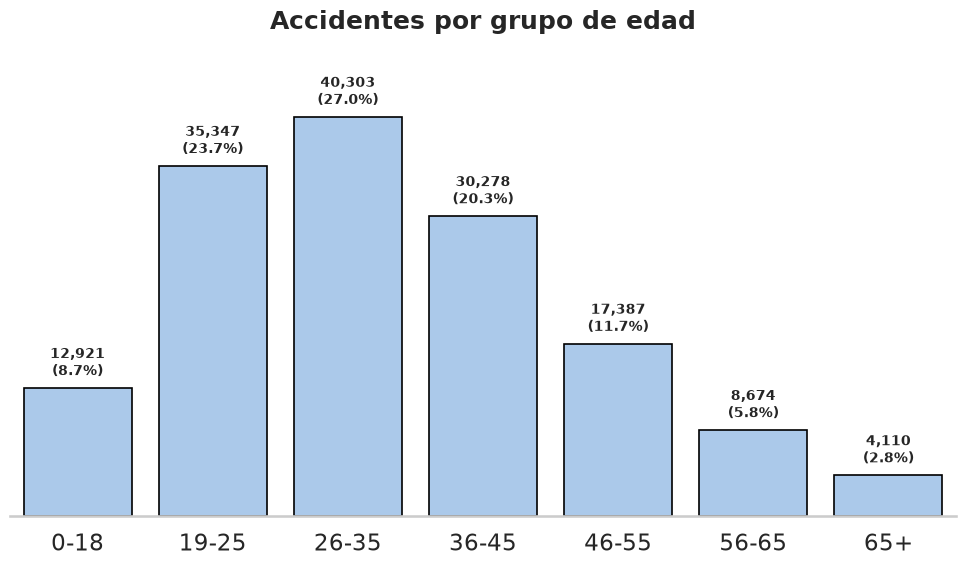

In [14]:
#Quitamos a aquellos con edad 0 y 99
edades = df['ID_EDAD'].replace([0, 99], np.nan)

bins = [0, 18, 25, 35, 45, 55, 65, 100]
labels = [
    '0-18',
    '19-25',
    '26-35',
    '36-45',
    '46-55',
    '56-65',
    '65+'
]

grupos = pd.cut(
    edades,
    bins=bins,
    labels=labels
)

conteos = grupos.value_counts().sort_index()
porcentajes = (conteos / conteos.sum() * 100).round(1)

fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    x=conteos.index,
    y=conteos.values,
    ax=ax,
    edgecolor='black',
    linewidth=1.2
)

for i, (valor, pct) in enumerate(zip(conteos.values, porcentajes.values)):
    ax.text(
        i,
        valor + conteos.max()*0.02,
        f'{int(valor):,}\n({pct}%)',
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

ax.set_title(
    'Accidentes por grupo de edad',
    fontsize=18,
    fontweight='bold',
    pad=20
)

ax.set_xlabel('')
ax.set_ylabel('')
ax.set_yticks([]) 

ax.set_ylim(0, conteos.max()*1.15)

ax.grid(axis='x', visible=False)

sns.despine(left=True, top=True)

plt.tight_layout()
plt.show()

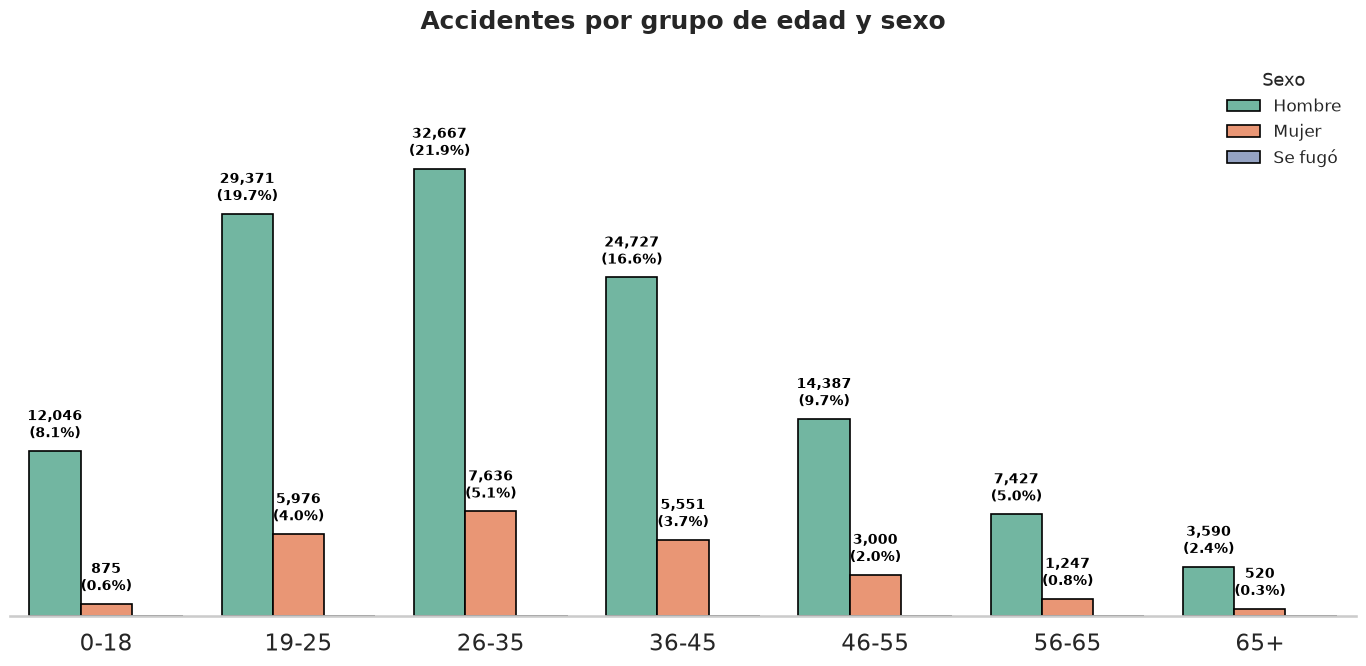

In [68]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# (Asumo que ya tienes df, los bins y labels creados)
# ...

datos_agrupados = df.groupby(['grupo_edad', 'SEXO'], observed=False).size().reset_index(name='conteo')
total_validos = datos_agrupados['conteo'].sum()
datos_agrupados['porcentaje'] = (datos_agrupados['conteo'] / total_validos * 100).round(1)

fig, ax = plt.subplots(figsize=(14, 7))

sns.barplot(
    data=datos_agrupados,
    x='grupo_edad',
    y='conteo',
    hue='SEXO',
    ax=ax,
    edgecolor='black',
    linewidth=1.2
)

# --- AQUÍ ESTÁ LA MAGIA ---
# Iteramos sobre cada barra dibujada
for bar in ax.patches:
    height = bar.get_height()
    
    # Si la barra está vacía (altura 0), la ignoramos
    if height == 0:
        continue
        
    # Obtenemos el centro de la barra en el eje X y su posición
    x_center = bar.get_x() + bar.get_width() / 2
    
    # Buscamos en nuestro DataFrame el registro que coincida con este valor exacto
    # (Filtramos por el valor de altura para encontrar el porcentaje correcto)
    pct = datos_agrupados.loc[datos_agrupados['conteo'] == height, 'porcentaje'].values[0]
    
    ax.text(
        x_center,
        height + (datos_agrupados['conteo'].max() * 0.02),
        f'{int(height):,}\n({pct}%)',
        ha='center', 
        va='bottom',
        fontsize=10,
        fontweight='bold',
        color='black'
    )
# --------------------------

ax.set_title('Accidentes por grupo de edad y sexo', fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_yticks([]) 
ax.set_ylim(0, datos_agrupados['conteo'].max() * 1.25)
ax.legend(title='Sexo', title_fontsize='13', fontsize='12', loc='upper right', frameon=False)
ax.grid(axis='x', visible=False)
sns.despine(left=True, top=True, bottom=False)

plt.tight_layout()
plt.show()

In [67]:
print(datos_agrupados)

   grupo_edad     SEXO  conteo  porcentaje
0        0-18   Hombre   12046         8.1
1        0-18    Mujer     875         0.6
2        0-18  Se fugó       0         0.0
3       19-25   Hombre   29371        19.7
4       19-25    Mujer    5976         4.0
5       19-25  Se fugó       0         0.0
6       26-35   Hombre   32667        21.9
7       26-35    Mujer    7636         5.1
8       26-35  Se fugó       0         0.0
9       36-45   Hombre   24727        16.6
10      36-45    Mujer    5551         3.7
11      36-45  Se fugó       0         0.0
12      46-55   Hombre   14387         9.7
13      46-55    Mujer    3000         2.0
14      46-55  Se fugó       0         0.0
15      56-65   Hombre    7427         5.0
16      56-65    Mujer    1247         0.8
17      56-65  Se fugó       0         0.0
18        65+   Hombre    3590         2.4
19        65+    Mujer     520         0.3
20        65+  Se fugó       0         0.0


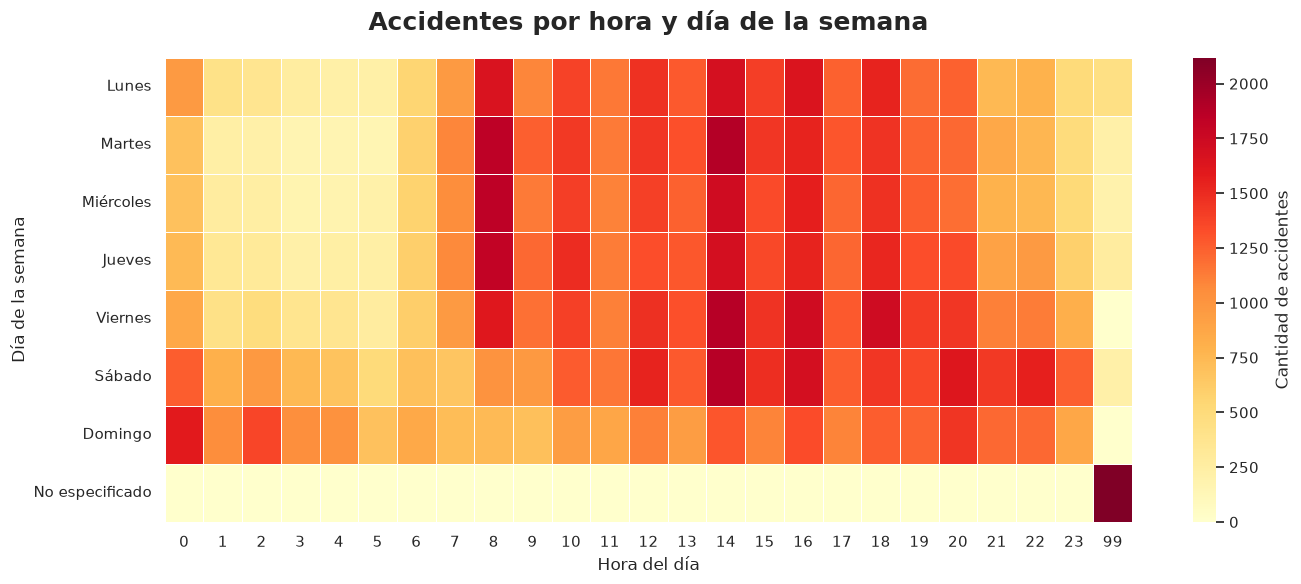

In [15]:
sns.set_theme(style="white")

tabla_horas = pd.crosstab(
    df['DIASEMANA'],
    df['ID_HORA']
)

tabla_horas = tabla_horas.reindex(orden_dias)

fig, ax = plt.subplots(figsize=(14, 6))

sns.heatmap(
    tabla_horas,
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={'label': 'Cantidad de accidentes'},
    ax=ax
)

ax.set_title(
    'Accidentes por hora y día de la semana',
    fontsize=18,
    fontweight='bold',
    pad=20
)

ax.set_xlabel('Hora del día')
ax.set_ylabel('Día de la semana')

plt.tight_layout()
plt.show()

Eliminamos esos dias y horas no especificados

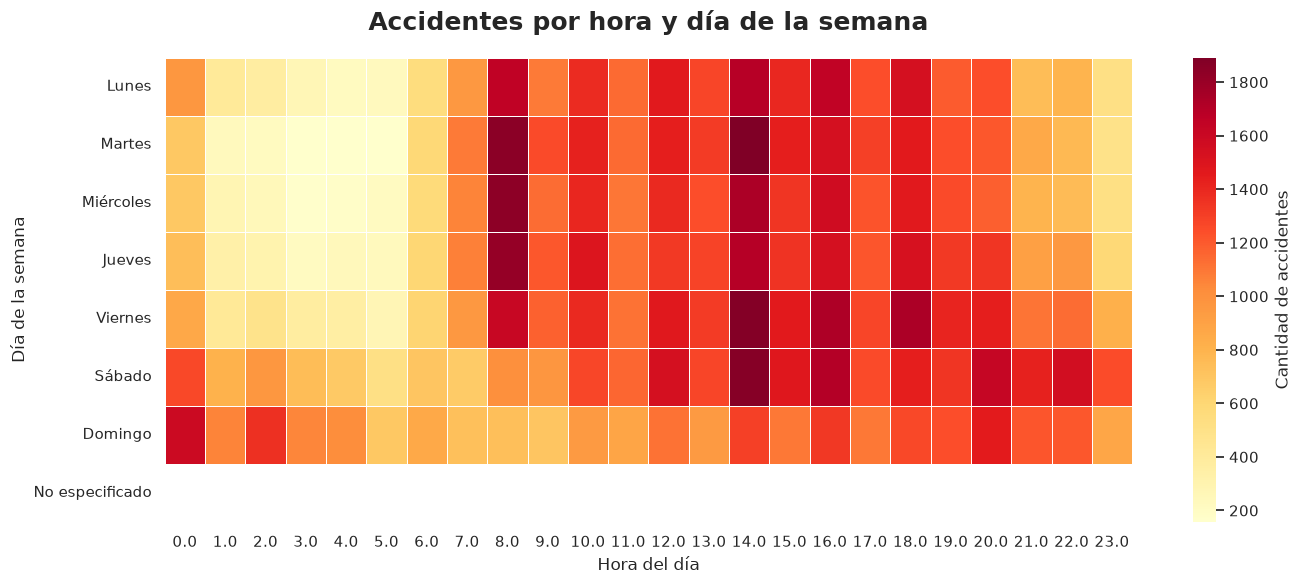

In [16]:
horas_dia = df['ID_HORA'].replace([99], np.nan)
dia_semana = df['DIASEMANA'].replace('No especificado',np.nan)

sns.set_theme(style="white")

tabla_horas = pd.crosstab(
    dia_semana,
    horas_dia
)

tabla_horas = tabla_horas.reindex(orden_dias)

fig, ax = plt.subplots(figsize=(14, 6))

sns.heatmap(
    tabla_horas,
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={'label': 'Cantidad de accidentes'},
    ax=ax
)

ax.set_title(
    'Accidentes por hora y día de la semana',
    fontsize=18,
    fontweight='bold',
    pad=20
)

ax.set_xlabel('Hora del día')
ax.set_ylabel('Día de la semana')

plt.tight_layout()
plt.show()